# Análisis de FEVER (Fact Extraction and VERification)

Objetivo: analizar los 50,000 extractos de Wikipedia del archivo `fever.jsonl` para seleccionar un subconjunto representativo para el pipeline de traducción.

## Contenido
1. Carga y parsing del JSONL
2. Distribución de longitudes (palabras y caracteres)
3. Clasificación temática automática (heurística por keywords en título y texto)
4. Estimación de costos (incluyendo estrategia de batching)
5. Criterios de selección y generación del subset
6. Exportación a `data/FEVER/selected/fever_selected.jsonl`

In [1]:
import json
import re
from pathlib import Path
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

plt.rcParams.update({"figure.dpi": 120, "figure.figsize": (12, 5)})

FEVER_FILE = Path("../data/FEVER/fever.jsonl")
print(f"Archivo: {FEVER_FILE}")
print(f"Tamaño: {FEVER_FILE.stat().st_size / (1024**2):.1f} MB")

Archivo: ../data/FEVER/fever.jsonl
Tamaño: 50.8 MB


## 1. Carga y parsing del JSONL

Cada línea contiene:
- `id`: título del artículo Wikipedia (con guiones bajos, ej. `1996_BellSouth_Open`)
- `text`: texto plano concatenado del artículo
- `lines`: versión tokenizada con anotaciones de entidades (para fact-checking)

Para traducción usamos solo `id` y `text`.

In [2]:
def clean_id(raw_id: str) -> str:
    """Convierte el id a título legible."""
    # Decodificar -LRB- / -RRB- (left/right bracket)
    s = raw_id.replace('-LRB-', '(').replace('-RRB-', ')')
    # Reemplazar guiones bajos por espacios
    s = s.replace('_', ' ')
    return s.strip()

# Cargar todos los artículos
records = []
with open(FEVER_FILE, encoding="utf-8") as f:
    for line in f:
        obj = json.loads(line)
        titulo = clean_id(obj["id"])
        text = obj["text"].strip()
        words = len(text.split()) if text else 0
        chars = len(text)
        records.append({
            "id": obj["id"],
            "titulo": titulo,
            "texto": text,
            "palabras": words,
            "caracteres": chars,
        })

df = pd.DataFrame(records)
print(f"Total de artículos: {len(df):,}")
print(f"Con texto no vacío: {(df['palabras'] > 0).sum():,}")
print(f"Vacíos (texto=''):   {(df['palabras'] == 0).sum():,}")
df.head(5)

Total de artículos: 50,000
Con texto no vacío: 48,178
Vacíos (texto=''):   1,822


,id,titulo,texto,palabras,caracteres
0,1996_BellSouth_Open,1996 BellSouth Open,The 1996 BellSouth Open was a tennis tournamen...,55,292
1,1994_Austrian_motorcycle_Grand_Prix,1994 Austrian motorcycle Grand Prix,The 1994 Austrian motorcycle Grand Prix was th...,30,160
2,1999_Detroit_Lions_season,1999 Detroit Lions season,The 1999 Detroit Lions season was their 70th i...,187,941
3,1985–86_Iraqi_National_League,1985–86 Iraqi National League,The 1985 -- 86 Iraqi National League was the 1...,61,332
4,1951_in_Malaya,1951 in Malaya,1951 in Malaya,3,14


## 2. Estadísticas descriptivas

In [3]:
df_nz = df[df["palabras"] > 0].copy()  # excluir vacíos

print("=" * 60)
print("ESTADÍSTICAS GENERALES (artículos con texto)")
print("=" * 60)
print(f"Total artículos:        {len(df):,}")
print(f"Con texto:              {len(df_nz):,}")
print(f"Total palabras:         {df_nz['palabras'].sum():,}")
print(f"Total caracteres:       {df_nz['caracteres'].sum():,}")
print()
print(df_nz[["palabras", "caracteres"]].describe().round(1).to_string())
print()
print("-" * 60)
print("PERCENTILES DE PALABRAS")
print("-" * 60)
for p in [1, 5, 10, 25, 50, 75, 90, 95, 99]:
    val = df_nz["palabras"].quantile(p / 100)
    print(f"  P{p:>2}: {val:>8,.0f} palabras")

ESTADÍSTICAS GENERALES (artículos con texto)
Total artículos:        50,000
Con texto:              48,178
Total palabras:         3,535,327
Total caracteres:       19,272,140

       palabras  caracteres
count   48178.0     48178.0
mean       73.4       400.0
std        94.5       498.0
min         1.0         1.0
25%        23.0       132.0
50%        48.0       261.0
75%        89.0       488.0
max      4600.0     21562.0

------------------------------------------------------------
PERCENTILES DE PALABRAS
------------------------------------------------------------
  P 1:        7 palabras
  P 5:        8 palabras
  P10:       11 palabras
  P25:       23 palabras
  P50:       48 palabras
  P75:       89 palabras
  P90:      158 palabras
  P95:      227 palabras
  P99:      415 palabras


In [4]:
# Tabla de rangos de tamaño
bins    = [0, 20, 50, 100, 200, 500, 1000, float("inf")]
labels  = ["<20", "20-50", "50-100", "100-200", "200-500", "500-1K", "1K+"]
df_nz["rango_palabras"] = pd.cut(df_nz["palabras"], bins=bins, labels=labels, right=False)

tabla_rangos = df_nz.groupby("rango_palabras", observed=False).agg(
    articulos=("id", "count"),
    palabras_total=("palabras", "sum"),
    media_palabras=("palabras", "mean"),
).reset_index()
tabla_rangos["pct_articulos"] = (tabla_rangos["articulos"] / len(df_nz) * 100).round(1)
tabla_rangos["pct_palabras"]  = (tabla_rangos["palabras_total"] / df_nz["palabras"].sum() * 100).round(1)

print("DISTRIBUCIÓN POR RANGO DE TAMAÑO")
print("=" * 80)
print(tabla_rangos.to_string(index=False))
print()
print("Nota: la mayoría de artículos FEVER son extractos muy cortos de Wikipedia.")
print("      Solo ~20% tiene >100 palabras, lo que los hace candidatos sólidos para traducción.")

DISTRIBUCIÓN POR RANGO DE TAMAÑO
rango_palabras  articulos  palabras_total  media_palabras  pct_articulos  pct_palabras
           <20       9738          113968       11.703430           20.2           3.2
         20-50      14906          506133       33.954985           30.9          14.3
        50-100      13278          931299       70.138500           27.6          26.3
       100-200       7173          978045      136.350899           14.9          27.7
       200-500       2833          817539      288.577127            5.9          23.1
        500-1K        219          131739      601.547945            0.5           3.7
           1K+         31           56604     1825.935484            0.1           1.6

Nota: la mayoría de artículos FEVER son extractos muy cortos de Wikipedia.
      Solo ~20% tiene >100 palabras, lo que los hace candidatos sólidos para traducción.


## 3. Distribución de longitudes

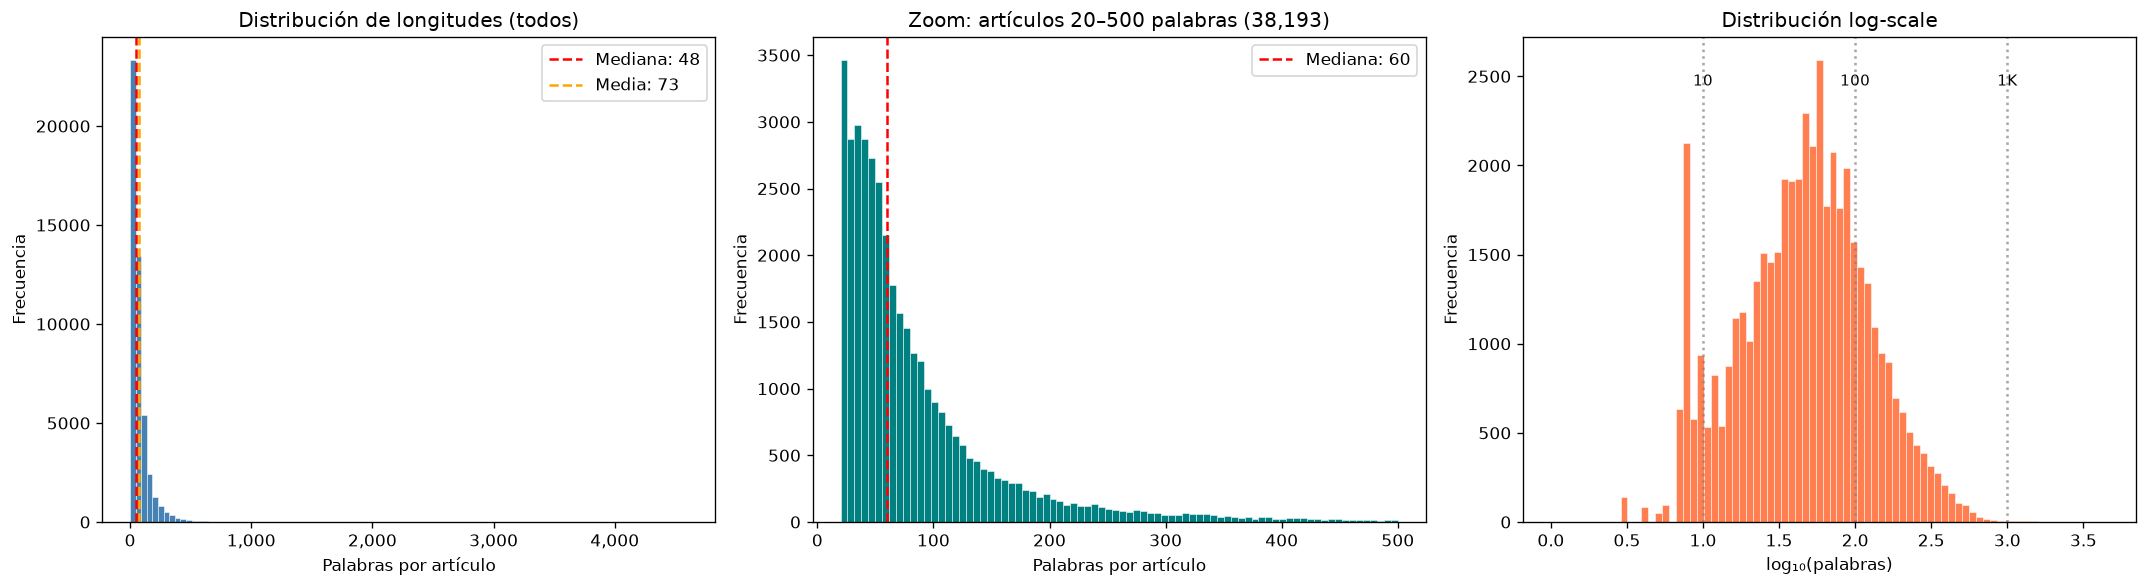

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 3a. Histograma general
ax = axes[0]
ax.hist(df_nz["palabras"], bins=100, color="steelblue", edgecolor="white", linewidth=0.3)
ax.set_xlabel("Palabras por artículo")
ax.set_ylabel("Frecuencia")
ax.set_title("Distribución de longitudes (todos)")
ax.axvline(df_nz["palabras"].median(), color="red",    linestyle="--", label=f'Mediana: {df_nz["palabras"].median():,.0f}')
ax.axvline(df_nz["palabras"].mean(),   color="orange", linestyle="--", label=f'Media: {df_nz["palabras"].mean():,.0f}')
ax.legend()
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

# 3b. Zoom: artículos con 20–500 palabras (mayor densidad)
ax = axes[1]
subset = df_nz[(df_nz["palabras"] >= 20) & (df_nz["palabras"] <= 500)]
ax.hist(subset["palabras"], bins=80, color="teal", edgecolor="white", linewidth=0.3)
ax.set_xlabel("Palabras por artículo")
ax.set_ylabel("Frecuencia")
ax.set_title(f"Zoom: artículos 20–500 palabras ({len(subset):,})")
ax.axvline(subset["palabras"].median(), color="red", linestyle="--", label=f'Mediana: {subset["palabras"].median():,.0f}')
ax.legend()

# 3c. Distribución log-scale
ax = axes[2]
ax.hist(np.log10(df_nz["palabras"].clip(lower=1)), bins=80, color="coral", edgecolor="white", linewidth=0.3)
ax.set_xlabel("log₁₀(palabras)")
ax.set_ylabel("Frecuencia")
ax.set_title("Distribución log-scale")
for val, label in [(1, "10"), (2, "100"), (3, "1K")]:
    ax.axvline(val, color="gray", linestyle=":", alpha=0.7)
    ax.text(val, ax.get_ylim()[1] * 0.9, label, ha="center", fontsize=9)

plt.tight_layout()
plt.show()

## 4. Clasificación temática (heurística por keywords)

Usamos keywords en el título (derivado del `id`) y el texto para clasificar por tema. FEVER está basado en Wikipedia, por lo que las mismas categorías que WikiText son válidas.

In [6]:
TOPIC_KEYWORDS = {
    "sports": [
        "football", "soccer", "baseball", "basketball", "tennis", "cricket",
        "olympic", "championship", "tournament", "league", "season", "coach",
        "player", "team", "match", "game ", "goalkeeper", "midfielder", "rugby",
        "nfl", "nba", "fifa", "batting", "bowling", "innings", "wicket",
        "medal", "sprint", "marathon", "hockey", "racing", "grand prix",
        "open ", "cup ", "series", "athletics", "swimming", "cycling",
        "golf", "boxing", "wrestling", "volleyball", "handball",
    ],
    "music": [
        "album", "song", "band", "singer", "music", "record", "billboard",
        "chart", "concert", "tour", "guitar", "vocalist", "hip hop", "rap",
        "symphony", "orchestra", "opera", "composer", "grammy", "single",
        "track", "remix", "genre", "punk", "metal", "jazz", "blues",
        "pop ", "rock ", "discography", "studio album",
    ],
    "film_tv": [
        "film", "movie", "actor", "actress", "director", "cinema", "box office",
        "television", "tv series", "episode", "sitcom", "drama",
        "screenplay", "oscar", "emmy", "netflix", "broadcast", "animated",
        "anime", "cartoon", "documentary",
    ],
    "military_history": [
        "battle", "war", "army", "navy", "military", "soldier", "regiment",
        "infantry", "artillery", "campaign", "invasion", "siege", "troop",
        "commander", "general", "admiral", "squadron", "fleet", "torpedo",
        "bomb", "aircraft carrier", "submarine", "division", "brigade",
    ],
    "science": [
        "species", "genus", "scientific", "research", "experiment", "theory",
        "molecule", "atom", "cell", "protein", "dna", "gene", "evolution",
        "fossil", "dinosaur", "chemistry", "physics", "biology", "ecology",
        "habitat", "conservation", "enzyme", "neuron", "quantum",
    ],
    "geography_places": [
        "city", "town", "village", "country", "island", "mountain", "river",
        "lake", "ocean", "continent", "population", "census", "district",
        "province", "county", "municipality", "capital", "located in",
        "commune", "parish", "borough",
    ],
    "technology": [
        "software", "computer", "programming", "internet", "algorithm",
        "processor", "database", "server", "network", "operating system",
        "video game", "playstation", "xbox", "nintendo", "console",
        "spacecraft", "satellite", "rocket", "nasa", "orbit",
    ],
    "politics_government": [
        "election", "president", "minister", "parliament", "congress",
        "senator", "governor", "political", "democrat", "republican",
        "legislation", "constitution", "vote", "campaign", "government",
    ],
    "biography": [
        "born", "died", "early life", "career", "personal life",
        "childhood", "education", "graduated", "married",
    ],
    "history": [
        "century", "empire", "dynasty", "kingdom", "colonial", "ancient",
        "medieval", "renaissance", "revolution", "independence", "treaty",
        "civilization", "archaeological",
    ],
    "religion_philosophy": [
        "church", "temple", "mosque", "religion", "god", "bible", "quran",
        "buddhist", "hindu", "christian", "jewish", "philosophy", "theology",
        "saint", "bishop", "pope", "monastery",
    ],
    "transport": [
        "railway", "railroad", "train", "station", "locomotive", "route",
        "highway", "airport", "airline", "ship", "vessel", "port", "bridge",
    ],
    "nature_weather": [
        "hurricane", "cyclone", "typhoon", "storm", "tornado", "earthquake",
        "flood", "drought", "climate", "tropical", "rainfall", "volcano",
    ],
}

def clasificar_tema(titulo: str, texto: str) -> str:
    """Clasifica por keywords en título + texto (primeros 500 chars)."""
    combined = (titulo + " " + texto[:500]).lower()
    scores = {}
    for topic, keywords in TOPIC_KEYWORDS.items():
        score = sum(1 for kw in keywords if kw in combined)
        if score > 0:
            scores[topic] = score
    if not scores:
        return "other"
    return max(scores, key=scores.get)

# Aplicar clasificación solo a artículos con texto
df_nz["tema"] = df_nz.apply(
    lambda row: clasificar_tema(row["titulo"], row["texto"]), axis=1
)

tema_counts = df_nz["tema"].value_counts()
print("DISTRIBUCIÓN TEMÁTICA (artículos con texto)")
print("=" * 55)
for tema, count in tema_counts.items():
    pct = count / len(df_nz) * 100
    print(f"  {tema:<25} {count:>7,}  ({pct:>5.1f}%)")
print(f"  {'TOTAL':<25} {len(df_nz):>7,}")

DISTRIBUCIÓN TEMÁTICA (artículos con texto)
  sports                     31,848  ( 66.1%)
  other                       6,290  ( 13.1%)
  military_history            2,656  (  5.5%)
  music                       2,195  (  4.6%)
  film_tv                     1,202  (  2.5%)
  geography_places            1,166  (  2.4%)
  transport                     780  (  1.6%)
  politics_government           570  (  1.2%)
  history                       429  (  0.9%)
  science                       342  (  0.7%)
  nature_weather                305  (  0.6%)
  technology                    214  (  0.4%)
  religion_philosophy           136  (  0.3%)
  biography                      45  (  0.1%)
  TOTAL                      48,178


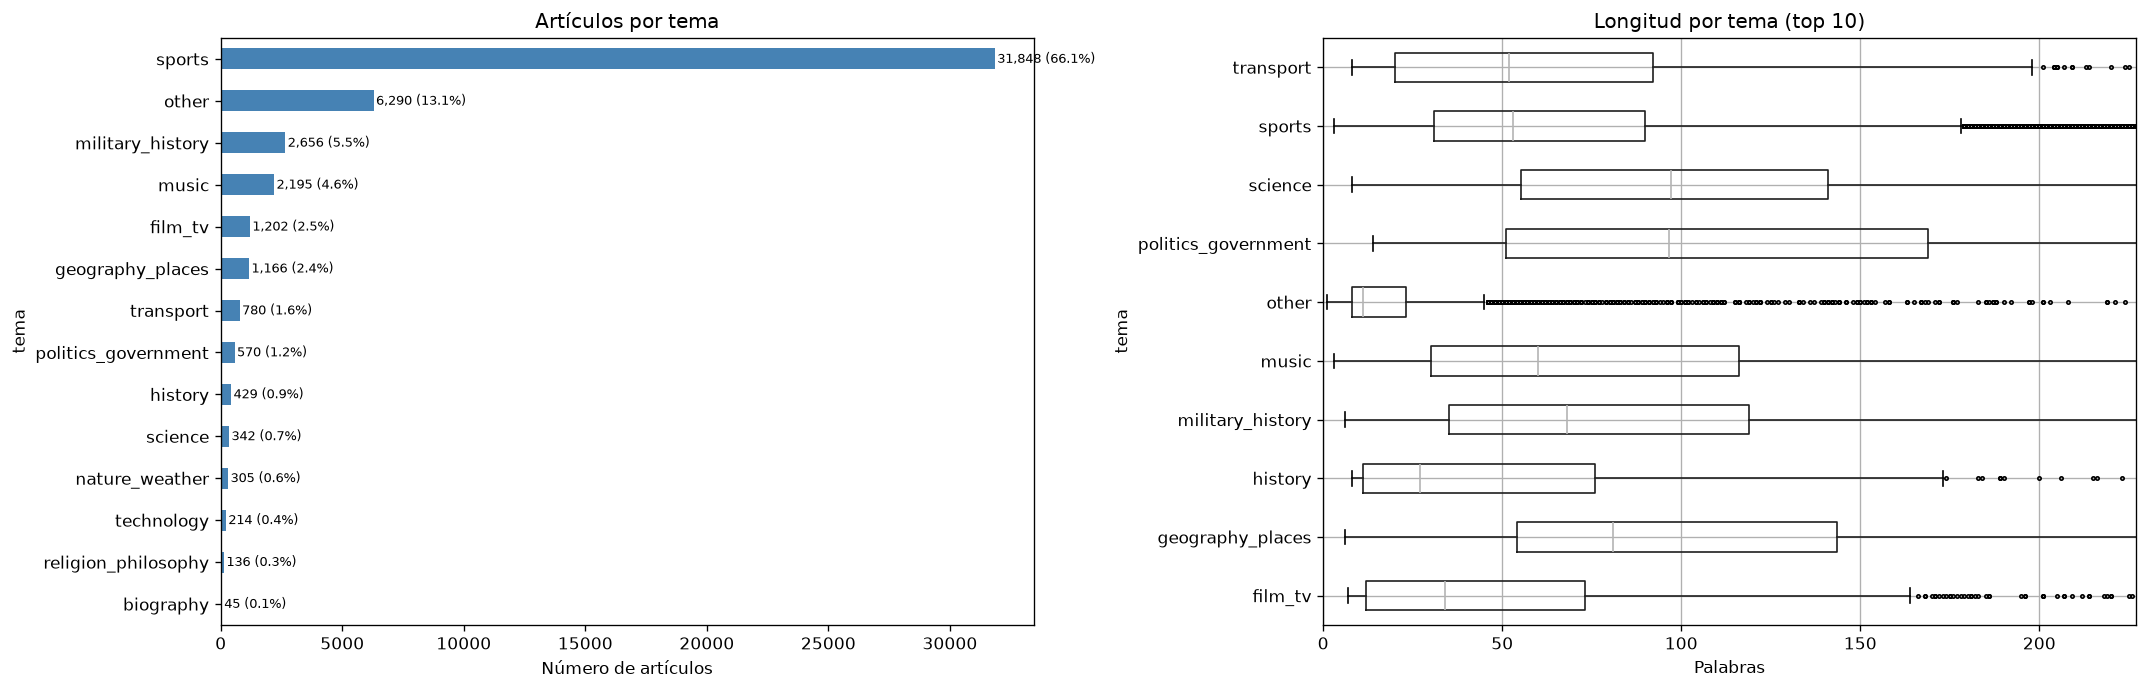

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Barplot de temas
ax = axes[0]
tema_counts.plot(kind="barh", ax=ax, color="steelblue")
ax.set_xlabel("Número de artículos")
ax.set_title("Artículos por tema")
ax.invert_yaxis()
for i, (count, tema) in enumerate(zip(tema_counts.values, tema_counts.index)):
    ax.text(count + 100, i, f"{count:,} ({count/len(df_nz)*100:.1f}%)", va="center", fontsize=8)

# Boxplot de palabras por tema (top temas)
ax = axes[1]
top_temas = tema_counts.head(10).index.tolist()
df_top = df_nz[df_nz["tema"].isin(top_temas)]
df_top.boxplot(column="palabras", by="tema", ax=ax, vert=False, flierprops=dict(markersize=2))
ax.set_xlabel("Palabras")
ax.set_title("Longitud por tema (top 10)")
ax.set_xlim(0, df_nz["palabras"].quantile(0.95))
plt.suptitle("")

plt.tight_layout()
plt.show()

## 5. Estimación de costos

FEVER presenta un reto especial: artículos muy cortos (mediana ~50 palabras).

**Estrategia de batching**: para reducir el número de llamadas al LLM se pueden empaquetar múltiples artículos en una sola llamada. Estimamos también el costo de batching vs. traducción individual.

In [8]:
# Estimación de tokens (~4 chars/token para inglés)
df_nz["tokens_est"] = (df_nz["caracteres"] / 4).astype(int)

# Pipeline individual (misma lógica que WikiText/Europarl):
# 3 traductores + 1 reviewer + 1 evaluador
PIPELINE_MULTIPLIER = 12
AVG_COST_PER_1M = 0.60 * 1.00 + 0.30 * 5.00 + 0.10 * 0.0  # $2.10/M tokens

df_nz["costo_individual_usd"] = df_nz["tokens_est"] * PIPELINE_MULTIPLIER * AVG_COST_PER_1M / 1_000_000

# Para batching: overhead fijo por batch (prompt del sistema ~500 tokens) + tokens del contenido
# Si agrupamos N artículos en una sola llamada, el overhead se amortiza
# Estimación simplificada: overhead_fijo=500 tokens por llamada, batch_size=10
BATCH_SIZE = 10
OVERHEAD_PER_CALL_TOKENS = 500

print("ESTIMACIÓN DE COSTOS POR RANGO (traducción individual)")
print("=" * 80)
cost_by_range = df_nz.groupby("rango_palabras", observed=False).agg(
    articulos=("id", "count"),
    tokens_total=("tokens_est", "sum"),
    costo_total=("costo_individual_usd", "sum"),
    costo_medio=("costo_individual_usd", "mean"),
).reset_index()
cost_by_range["tokens_total"] = cost_by_range["tokens_total"].map(lambda x: f"{x:,.0f}")
cost_by_range["costo_total"]  = cost_by_range["costo_total"].map(lambda x: f"${x:,.2f}")
cost_by_range["costo_medio"]  = cost_by_range["costo_medio"].map(lambda x: f"${x:,.4f}")
print(cost_by_range.to_string(index=False))

total_costo = df_nz["costo_individual_usd"].sum()
print(f"\n{'─' * 80}")
print(f"Costo estimado TOTAL individual (todos los artículos): ${total_costo:,.2f} USD")
print(f"Costo estimado promedio por artículo:                  ${df_nz['costo_individual_usd'].mean():,.4f} USD")
print()
print(f"Nota: con batching de {BATCH_SIZE} artículos/llamada el costo de overhead se reduce ~{BATCH_SIZE}x.")

ESTIMACIÓN DE COSTOS POR RANGO (traducción individual)
rango_palabras  articulos tokens_total costo_total costo_medio
           <20       9738      151,456       $3.82     $0.0004
         20-50      14906      682,436      $17.20     $0.0012
        50-100      13278    1,267,046      $31.93     $0.0024
       100-200       7173    1,337,301      $33.70     $0.0047
       200-500       2833    1,115,632      $28.11     $0.0099
        500-1K        219      178,109       $4.49     $0.0205
           1K+         31       67,792       $1.71     $0.0551

────────────────────────────────────────────────────────────────────────────────
Costo estimado TOTAL individual (todos los artículos): $120.95 USD
Costo estimado promedio por artículo:                  $0.0025 USD

Nota: con batching de 10 artículos/llamada el costo de overhead se reduce ~10x.


## 6. Selección de artículos

### Estrategia: muestreo estratificado por tema y tamaño

**Criterios de filtrado:**
- Descartar artículos con **< 50 palabras** (fragmentos, sin contexto suficiente para traducción)
- No hay límite superior relevante (el máximo es ~3K palabras)

**Criterios de muestreo:**
- Muestreo **proporcional por tema**
- Dentro de cada tema, muestreo **estratificado por tamaño** (bins)

**Tamaño del subset**: dado que los artículos son cortos, se puede seleccionar más que en las otras fuentes.

In [16]:
# ── Parámetros de selección (ajustables) ──
MIN_PALABRAS = 100
MAX_PALABRAS = 10_000   # no hay límite práctico en FEVER
N_SELECCION  = 10000     # más artículos porque son cortos
SEED         = 42

# Filtrar rango útil
df_filtrado = df_nz[
    (df_nz["palabras"] >= MIN_PALABRAS) &
    (df_nz["palabras"] <= MAX_PALABRAS)
].copy()
print(f"Artículos en rango [{MIN_PALABRAS:,}–{MAX_PALABRAS:,}] palabras: {len(df_filtrado):,} / {len(df_nz):,}")
print(f"Descartados: {len(df_nz) - len(df_filtrado):,} ({(len(df_nz) - len(df_filtrado)) / len(df_nz) * 100:.1f}%)")

if len(df_filtrado) < N_SELECCION:
    print(f"\nADVERTENCIA: Solo {len(df_filtrado):,} artículos disponibles, menos que {N_SELECCION:,} solicitados.")
    print("Ajusta MIN_PALABRAS o N_SELECCION.")

# Bins de tamaño
size_bins   = [MIN_PALABRAS, 200, 500, 1000, MAX_PALABRAS + 1]
size_labels = ["pequeño (50-100)", "mediano (100-200)", "grande (200-500)", "muy grande (500+)"]
df_filtrado["bin_size"] = pd.cut(df_filtrado["palabras"], bins=size_bins, labels=size_labels, right=False)

print(f"\nDistribución del pool filtrado:")
print("-" * 55)
for tema in sorted(df_filtrado["tema"].unique()):
    n = len(df_filtrado[df_filtrado["tema"] == tema])
    print(f"  {tema:<25} {n:>7,}  ({n/len(df_filtrado)*100:>5.1f}%)")

Artículos en rango [100–10,000] palabras: 10,256 / 48,178
Descartados: 37,922 (78.7%)

Distribución del pool filtrado:
-------------------------------------------------------
  biography                      18  (  0.2%)
  film_tv                       199  (  1.9%)
  geography_places              470  (  4.6%)
  history                        55  (  0.5%)
  military_history              860  (  8.4%)
  music                         685  (  6.7%)
  nature_weather                206  (  2.0%)
  other                         181  (  1.8%)
  politics_government           279  (  2.7%)
  religion_philosophy            21  (  0.2%)
  science                       166  (  1.6%)
  sports                      6,834  ( 66.6%)
  technology                    108  (  1.1%)
  transport                     174  (  1.7%)


In [17]:
# Muestreo estratificado: proporcional por tema, dentro de cada tema por tamaño

n_seleccion_real = min(N_SELECCION, len(df_filtrado))

# Calcular cuota por tema (proporcional)
tema_fracs  = df_filtrado["tema"].value_counts(normalize=True)
tema_cuotas = (tema_fracs * n_seleccion_real).round().astype(int)
diff = n_seleccion_real - tema_cuotas.sum()
if diff != 0:
    tema_cuotas.iloc[0] += diff

print("Cuotas por tema:")
print("-" * 55)
for tema, cuota in tema_cuotas.items():
    pool = len(df_filtrado[df_filtrado["tema"] == tema])
    print(f"  {tema:<25} {cuota:>5} / {pool:>7,} disponibles")
print(f"  {'TOTAL':<25} {tema_cuotas.sum():>5}")

# Ejecutar muestreo
seleccionados = []
for tema, cuota in tema_cuotas.items():
    pool_tema = df_filtrado[df_filtrado["tema"] == tema]
    if len(pool_tema) <= cuota:
        seleccionados.append(pool_tema)
        continue

    muestras_tema = []
    bin_counts  = pool_tema["bin_size"].value_counts()
    bin_fracs   = bin_counts / bin_counts.sum()
    bin_cuotas  = (bin_fracs * cuota).round().astype(int)
    diff_bin    = cuota - bin_cuotas.sum()
    if diff_bin != 0:
        bin_cuotas.iloc[0] += diff_bin

    for bin_label, bin_cuota in bin_cuotas.items():
        pool_bin = pool_tema[pool_tema["bin_size"] == bin_label]
        n_sample = min(bin_cuota, len(pool_bin))
        if n_sample > 0:
            muestra = pool_bin.sample(n=n_sample, random_state=SEED)
            muestras_tema.append(muestra)

    if muestras_tema:
        tema_df = pd.concat(muestras_tema)
        if len(tema_df) < cuota:
            faltantes = cuota - len(tema_df)
            restantes = pool_tema[~pool_tema.index.isin(tema_df.index)]
            extra     = restantes.sample(n=min(faltantes, len(restantes)), random_state=SEED)
            tema_df   = pd.concat([tema_df, extra])
        seleccionados.append(tema_df)

df_seleccion = pd.concat(seleccionados).reset_index(drop=True)
print(f"\nSeleccionados: {len(df_seleccion):,} artículos")

Cuotas por tema:
-------------------------------------------------------
  sports                     6663 /   6,834 disponibles
  military_history            839 /     860 disponibles
  music                       668 /     685 disponibles
  geography_places            458 /     470 disponibles
  politics_government         272 /     279 disponibles
  nature_weather              201 /     206 disponibles
  film_tv                     194 /     199 disponibles
  other                       176 /     181 disponibles
  transport                   170 /     174 disponibles
  science                     162 /     166 disponibles
  technology                  105 /     108 disponibles
  history                      54 /      55 disponibles
  religion_philosophy          20 /      21 disponibles
  biography                    18 /      18 disponibles
  TOTAL                     10000

Seleccionados: 10,000 artículos


## 7. Validación de la selección

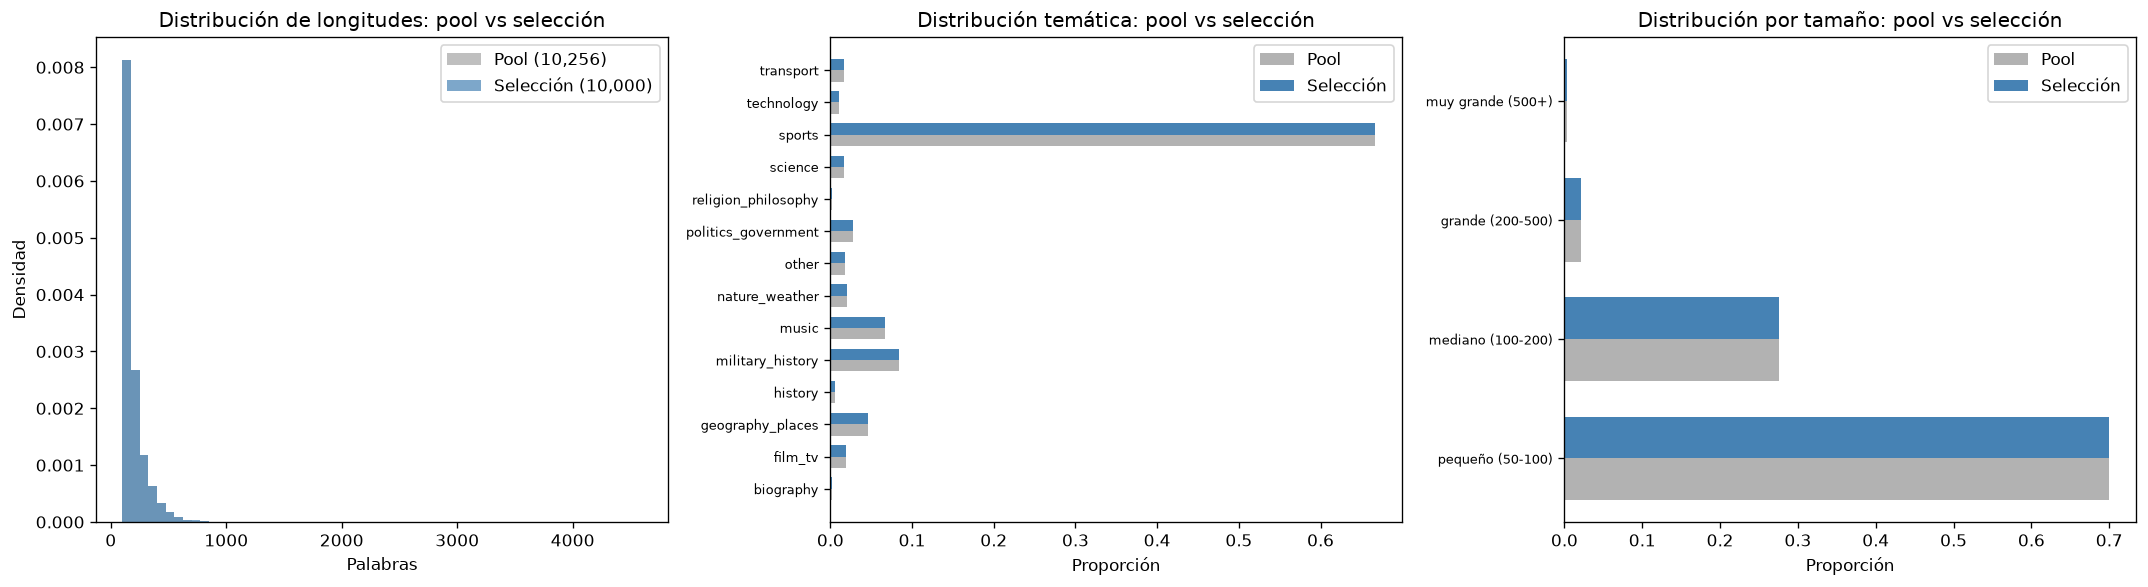


RESUMEN DE LA SELECCIÓN
Artículos seleccionados:   10,000
Palabras totales:          1,931,615
Tokens estimados:          2,628,756
Costo estimado pipeline:   $66.24 USD (traducción individual)
Rango de palabras:         [100 – 4,600]
Temas representados:       14
Media palabras/artículo:   193
Mediana palabras/artículo: 152

Nota de batching: con batch_size=10 artículos por llamada,
  se harían ~1,000 llamadas en lugar de 10,000


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Comparar distribución de palabras
ax = axes[0]
ax.hist(df_filtrado["palabras"], bins=60, alpha=0.5, label=f"Pool ({len(df_filtrado):,})",       color="gray",      density=True)
ax.hist(df_seleccion["palabras"], bins=60, alpha=0.7, label=f"Selección ({len(df_seleccion):,})", color="steelblue", density=True)
ax.set_xlabel("Palabras")
ax.set_ylabel("Densidad")
ax.set_title("Distribución de longitudes: pool vs selección")
ax.legend()

# Comparar distribución de temas
ax = axes[1]
pool_temas = df_filtrado["tema"].value_counts(normalize=True).sort_index()
sel_temas  = df_seleccion["tema"].value_counts(normalize=True).sort_index()
x = np.arange(len(pool_temas))
w = 0.35
ax.barh(x - w/2, pool_temas.values, w, label="Pool",      color="gray",      alpha=0.6)
ax.barh(x + w/2, sel_temas.reindex(pool_temas.index, fill_value=0).values, w, label="Selección", color="steelblue")
ax.set_yticks(x)
ax.set_yticklabels(pool_temas.index, fontsize=8)
ax.set_xlabel("Proporción")
ax.set_title("Distribución temática: pool vs selección")
ax.legend()

# Distribución por bin de tamaño
ax = axes[2]
pool_bins = df_filtrado["bin_size"].value_counts(normalize=True).sort_index()
sel_bins  = df_seleccion["bin_size"].value_counts(normalize=True).sort_index()
x = np.arange(len(pool_bins))
ax.barh(x - w/2, pool_bins.values, w, label="Pool",      color="gray",      alpha=0.6)
ax.barh(x + w/2, sel_bins.reindex(pool_bins.index, fill_value=0).values, w, label="Selección", color="steelblue")
ax.set_yticks(x)
ax.set_yticklabels(pool_bins.index, fontsize=8)
ax.set_xlabel("Proporción")
ax.set_title("Distribución por tamaño: pool vs selección")
ax.legend()

plt.tight_layout()
plt.show()

# Estadísticas resumen
costo_sel = (df_seleccion["tokens_est"] * PIPELINE_MULTIPLIER * AVG_COST_PER_1M / 1_000_000).sum()
print("\nRESUMEN DE LA SELECCIÓN")
print("=" * 60)
print(f"Artículos seleccionados:   {len(df_seleccion):,}")
print(f"Palabras totales:          {df_seleccion['palabras'].sum():,}")
print(f"Tokens estimados:          {df_seleccion['tokens_est'].sum():,}")
print(f"Costo estimado pipeline:   ${costo_sel:,.2f} USD (traducción individual)")
print(f"Rango de palabras:         [{df_seleccion['palabras'].min():,} – {df_seleccion['palabras'].max():,}]")
print(f"Temas representados:       {df_seleccion['tema'].nunique()}")
print(f"Media palabras/artículo:   {df_seleccion['palabras'].mean():,.0f}")
print(f"Mediana palabras/artículo: {df_seleccion['palabras'].median():,.0f}")
print()
print(f"Nota de batching: con batch_size={BATCH_SIZE} artículos por llamada,")
print(f"  se harían ~{len(df_seleccion)//BATCH_SIZE:,} llamadas en lugar de {len(df_seleccion):,}")

## 8. Exportar artículos seleccionados

Genera un archivo `fever_selected.jsonl` con los artículos seleccionados y un CSV con metadatos.

In [19]:
import shutil

OUTPUT_DIR  = Path("../data/FEVER/selected")
OUTPUT_FILE = OUTPUT_DIR / "fever_selected.jsonl"
OUTPUT_CSV  = Path("fever_seleccion.csv")

# Crear directorio
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Construir un dict de id -> texto original para recuperar el campo 'lines'
# (por si el agente de traducción lo necesita en el futuro)
id_to_original = {}
with open(FEVER_FILE, encoding="utf-8") as f:
    for line in f:
        obj = json.loads(line)
        id_to_original[obj["id"]] = obj

# Escribir JSONL seleccionado (orden original del archivo fuente)
ids_sel = set(df_seleccion["id"].values)
written = 0
with open(OUTPUT_FILE, "w", encoding="utf-8") as out:
    for raw_id, obj in id_to_original.items():
        if raw_id in ids_sel:
            out.write(json.dumps(obj, ensure_ascii=False) + "\n")
            written += 1

size_kb = OUTPUT_FILE.stat().st_size / 1024
print(f"Archivo JSONL exportado: {OUTPUT_FILE}")
print(f"  Artículos: {written:,}")
print(f"  Tamaño: {size_kb:.1f} KB")

# Exportar CSV con metadatos
cols_export = ["id", "titulo", "palabras", "caracteres", "tema", "bin_size", "tokens_est"]
df_seleccion.sort_values("id")[cols_export].to_csv(OUTPUT_CSV, index=False, encoding="utf-8")
print(f"\nCSV de metadatos: {OUTPUT_CSV}")

print(f"\nListo para implementar el agente de traducción:")
print(f"  Entrada: {OUTPUT_FILE}")
print(f"  Salida:  output/FEVER/")

Archivo JSONL exportado: ../data/FEVER/selected/fever_selected.jsonl
  Artículos: 10,000
  Tamaño: 26473.5 KB

CSV de metadatos: fever_seleccion.csv

Listo para implementar el agente de traducción:
  Entrada: ../data/FEVER/selected/fever_selected.jsonl
  Salida:  output/FEVER/
